# Classifying ECG beats with convolution and recurrence

Which temporal representation separates the five ECG5000 classes under a beat-level split?

I compare a 1D CNN with a bidirectional GRU and a logistic regression baseline. Class weights come from the training split, and macro F1 complements accuracy under the uneven class counts.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset
from sklearn.metrics import classification_report, confusion_matrix

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    classification_scores,
    plot_history,
    predict,
    seed_everything,
    split_tensors,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "06_ecg_sequence_classification"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## ECG5000 and preprocessing

The course CSV contains one class label followed by 140 signal amplitudes. Labels 1 to 5 are converted to indices 0 to 4. The existing per-beat amplitude scaling is preserved; an additional feature scaler is fitted only on the training subset. There are no patient identifiers in this file, so this split measures beat-level generalization.

torch.Size([5000, 140]) [2919, 1767, 96, 194, 24]


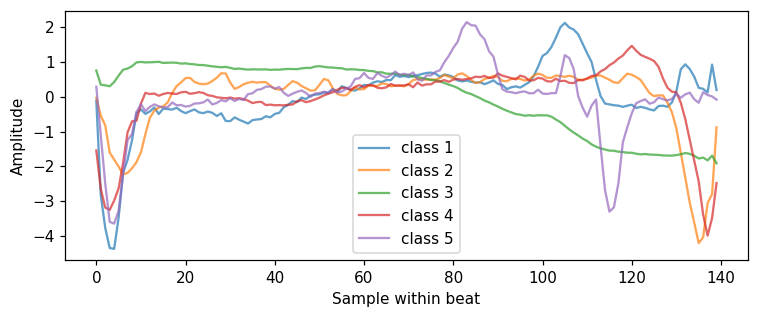

In [5]:
from deep_projects.data import ecg_data
from sklearn.preprocessing import StandardScaler

signals, labels = ecg_data(root / "data" / "ECG5000.csv")
data = split_tensors(signals, labels)
scaler = StandardScaler().fit(data.train.tensors[0].numpy())
standardized = []
for dataset in [data.train, data.validation, data.test]:
    values, targets = dataset.tensors
    standardized.append(
        TensorDataset(
            torch.tensor(scaler.transform(values.numpy()), dtype=torch.float32), targets
        )
    )
data = DataSplit(*standardized)
print(signals.shape, torch.bincount(labels).tolist())
fig, axis = plt.subplots(figsize=(7, 3))
for label in labels.unique():
    example = signals[torch.where(labels == label)[0][0]]
    axis.plot(example.numpy(), label=f"class {int(label) + 1}", alpha=0.7)
axis.set(xlabel="Sample within beat", ylabel="Amplitude")
axis.legend()
fig.tight_layout()
fig.savefig(output / "signals.png", dpi=140)
plt.show()

## Signal models

The CNN detects local waveform patterns and pools them. The bidirectional GRU reads a complete beat in both directions, which is appropriate when the full input is already available. It would use future samples in a streaming deployment.

class SignalGRU(nn.Module):
    def __init__(self, classes=5):
        super().__init__()
        self.recurrent = nn.GRU(1, 24, batch_first=True, bidirectional=True)
        self.classifier = nn.Linear(48, classes)

    def forward(self, signals):
        _, hidden = self.recurrent(signals.unsqueeze(-1))
        return self.classifier(torch.cat([hidden[-2], hidden[-1]], dim=-1))



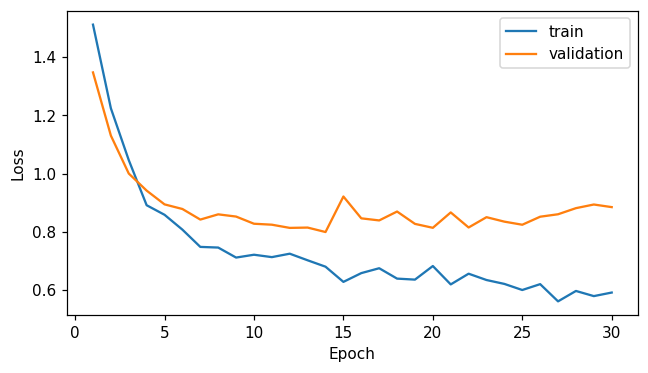

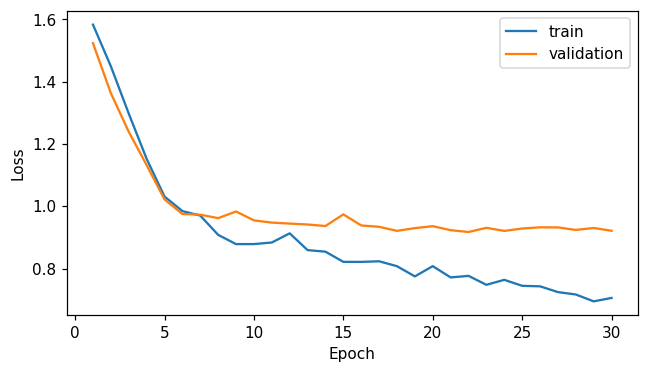

               model  accuracy  macro_f1       nll
0                cnn     0.912  0.556389  0.347448
1  bidirectional_gru     0.865  0.505782  0.506173 selected: cnn


In [7]:
from deep_projects.models import SignalCNN, SignalGRU

print(inspect.getsource(SignalGRU))
train_loader, validation_loader, test_loader = data.loaders(64)
frequencies = torch.bincount(data.train.tensors[1], minlength=5).float()
weights = frequencies.sum() / (5 * frequencies)
trained, rows = {}, []
for name, constructor in [("cnn", SignalCNN), ("bidirectional_gru", SignalGRU)]:
    seed_everything()
    model = constructor()
    train_loader, validation_loader, test_loader = data.loaders()
    history = Trainer(
        model,
        nn.CrossEntropyLoss(weight=weights),
        TrainConfig(epochs=3 if QUICK else 30, learning_rate=0.001),
    ).fit(train_loader, validation_loader)
    plot_history(history, output / f"{name}_loss.png")
    logits, labels = predict(model, validation_loader)
    rows.append({"model": name, **classification_scores(logits, labels)})
    trained[name] = model
selected = max(rows, key=lambda row: row["macro_f1"])["model"]
print(pd.DataFrame(rows), "selected:", selected)

## A linear reference

Logistic regression receives the same standardized amplitudes. Its regularization is fixed before testing. This baseline helps establish whether the neural temporal structure adds useful information on these aligned beats.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

baseline = LogisticRegression(max_iter=2000, class_weight="balanced", C=1)
baseline.fit(data.train.tensors[0], data.train.tensors[1])
baseline_predictions = baseline.predict(data.test.tensors[0])
model = trained[selected]
logits, labels = predict(model, test_loader)
scores = classification_scores(logits, labels)
print(classification_report(labels, logits.argmax(-1), zero_division=0))
results = {
    "validation": rows,
    "selected": selected,
    "test": scores,
    "linear": {
        "accuracy": float(accuracy_score(labels, baseline_predictions)),
        "macro_f1": float(f1_score(labels, baseline_predictions, average="macro")),
    },
}
print(results)

              precision    recall  f1-score   support

           0       0.99      0.97      0.98       584
           1       0.94      0.90      0.92       353
           2       0.29      0.63      0.40        19
           3       0.39      0.41      0.40        39
           4       0.00      0.00      0.00         5

    accuracy                           0.91      1000
   macro avg       0.52      0.58      0.54      1000
weighted avg       0.93      0.91      0.92      1000

{'validation': [{'model': 'cnn', 'accuracy': 0.912, 'macro_f1': 0.5563885581132235, 'nll': 0.3474479893101816}, {'model': 'bidirectional_gru', 'accuracy': 0.865, 'macro_f1': 0.5057818199962013, 'nll': 0.5061734911147959}], 'selected': 'cnn', 'test': {'accuracy': 0.91, 'macro_f1': 0.5398417602290709, 'nll': 0.35741071924880186}, 'linear': {'accuracy': 0.892, 'macro_f1': 0.5816820231114852}}


## Classwise mistakes

The matrix shows minority-class errors directly. The normalization is by true class count so each row sums to one; absolute sample counts remain available in the classification report.

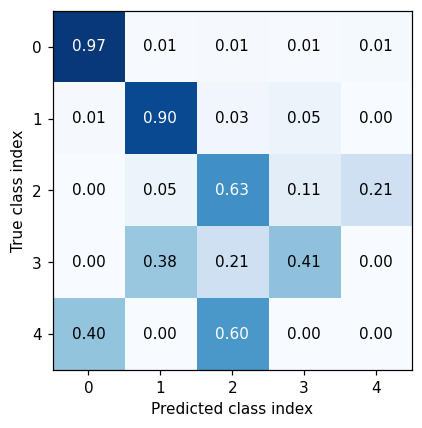

In [11]:
matrix = confusion_matrix(labels, logits.argmax(-1), labels=np.arange(5))
normalized = matrix / matrix.sum(axis=1, keepdims=True)
fig, axis = plt.subplots(figsize=(5, 4))
axis.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
for row in range(5):
    for column in range(5):
        axis.text(
            column,
            row,
            f"{normalized[row, column]:.2f}",
            ha="center",
            va="center",
            color="white" if normalized[row, column] > 0.5 else "black",
        )
axis.set(xlabel="Predicted class index", ylabel="True class index")
fig.tight_layout()
fig.savefig(output / "confusion.png", dpi=140)
plt.show()

## Reading the result

Macro F1 gives each class equal weight, while accuracy follows the observed prevalence. A beat-level split can share patient-specific characteristics across subsets. The available CSV cannot quantify performance on unseen patients.

Recorded run: Validation macro F1 selected the 1D CNN. Its test accuracy was 91.0%, while macro F1 was about 0.540. The linear baseline had lower accuracy but higher macro F1, about 0.582. The different rankings reflect uneven class sizes and show why accuracy alone is insufficient here.

In [13]:
result_path = root / "results" / "06_ecg_sequence_classification.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/06_ecg_sequence_classification.json


## Next experiment

Compare against the original recurrent architecture on a dataset with patient identifiers. Split by patient before any scaling or beat cropping, then tune class weights using validation performance.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_5 and Lab_7.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.